# 01 · Data preparation & EDA

**Project.** Can synthetic chest X-rays (from a generative model trained on hospital A) make a pneumonia classifier generalise better to a *different* hospital (B)? This notebook prepares the data that every later experiment depends on. Most of the scientific risk sits here: leakage, label mismatch and shortcuts decide whether any later comparison is meaningful.

**Why two datasets?** A model is trained and tuned on A only. B plays the role of "a new hospital the model has never seen": a different country, age group, scanners and labelling process. The gap between A and B performance is the quantity the project tries to shrink.

| Role | Dataset | Use |
|---|---|---|
| **A — source** | Kermany / Guangzhou pediatric CXR (`data/kaggle/chest_xray`) | classifier training, validation (model selection + threshold), internal test |
| **B — external** | RSNA Pneumonia Detection Challenge, adjudicated MD.ai export (NIH ChestX-ray14 subset, adults) | external test only: never used to train, tune or select |

Outputs
* `artifacts/manifests/kermany.csv`: one row per A image, with patient-grouped `split` and the fixed `subset_1k` training subset
* `artifacts/manifests/rsna_labels.csv`: harmonised B labels (from the annotation JSON)
* `artifacts/manifests/rsna.csv`: B manifest (built once the image archive is extracted to `data/rsna/`)
* `artifacts/cache/*.npy`: preprocessed 224×224 uint8 images
* `reports/figures/*.png`

In [1]:
import sys, re, json, collections
from pathlib import Path
from multiprocessing import Pool

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

from cxr.imaging import image_stats, load_gray, to_square
from cxr.data import ensure_cache

SEED = 0
IMAGE_SIZE, RESIZE_MODE = 224, "squash"
DUP_THRESHOLD = 0.99        # thumbnail cosine similarity; justified in section 3
SUBSET_PER_CLASS = 500      # fixed limited-data training subset: 500 normal + 500 pneumonia patients
VAL_FOLDS = 7               # 1/7 of the patient-grouped training pool -> validation

A_DIR = ROOT / "data/kaggle/chest_xray"
B_JSON = ROOT / "data/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
B_DIR = ROOT / "data/rsna"   # extract the RSNA image archive here
MANIFESTS, FIG = ROOT / "artifacts/manifests", ROOT / "reports/figures"
for d in (MANIFESTS, FIG):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Dataset A: inventory

File names encode the patient: `personN_{bacteria|virus}_K.jpeg` for pneumonia and `[NORMAL2-]IM-XXXX-YYYY.jpeg` for normal.
The official `val/` folder has only 16 images, which is too small for model selection, so it is pooled with `train/` and re-split by patient below.

In [2]:
def patient_of(name: str) -> str:
    m = re.match(r"(person\d+)_", name) or re.match(r"((?:NORMAL2-)?IM-\d+)-", name)
    return m.group(1)

rows = []
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        for p in sorted((A_DIR / split / cls).glob("*.jpeg")):
            sub = "normal" if cls == "NORMAL" else ("bacteria" if "_bacteria_" in p.name else "virus")
            rows.append({"image_id": f"A/{split}/{p.stem}", "image_path": str(p.relative_to(ROOT)),
                         "label": int(cls == "PNEUMONIA"), "orig_label": sub, "source": "kermany",
                         "official_split": split, "patient_id": patient_of(p.name)})
a = pd.DataFrame(rows)

with Pool(12) as pool:
    stats = pool.map(image_stats, [ROOT / p for p in a.image_path], chunksize=32)
thumbs = np.stack([s.pop("thumb") for s in stats])
a = pd.concat([a, pd.DataFrame(stats)], axis=1)
a["aspect"] = a.width / a.height

summary = a.groupby(["official_split", "orig_label"]).agg(images=("image_id", "size"), patients=("patient_id", "nunique"))
display(summary.unstack(0))
print("pixel modes:", a["mode"].value_counts().to_dict())
print(f"pneumonia prevalence: {a.label.mean():.1%} overall; images/patient: "
      f"normal {a[a.label==0].groupby('patient_id').size().mean():.2f}, "
      f"pneumonia {a[a.label==1].groupby('patient_id').size().mean():.2f}")

images              patients             
official_split   test   train  val     test   train  val
orig_label                                              
bacteria        242.0  2530.0  8.0     77.0  1353.0  7.0
normal          234.0  1341.0  8.0    225.0  1211.0  8.0
virus           148.0  1345.0  NaN    126.0  1090.0  NaN

pixel modes: {'L': 5573, 'RGB': 283}
pneumonia prevalence: 73.0% overall; images/patient: normal 1.10, pneumonia 2.55


**What the inventory shows**
* **Class imbalance.** About 73% of A images are pneumonia. Imbalance does not affect AUROC, but it shifts the score distribution and the default 0.5 threshold. This is one reason the decision threshold is chosen on validation data (Youden's J) instead of using 0.5, and one reason E1 uses a *balanced* subset.
* **Several images per patient.** Pneumonia patients have about 2.5 images each, normal patients about 1.1. Images of the same child are strongly correlated, so splitting by *image* would let near-copies of a training patient appear in validation or test and inflate every metric. All splits below are therefore by patient.
* **Pathogen subtype.** "bacteria" and "virus" are kept only as metadata (`orig_label`). The task is binary (pneumonia vs normal), but subtype is used later in the error analysis: viral pneumonia is usually subtler on X-ray.
* **283 images are stored as RGB.** They are converted to grayscale on load. Colour carries no information in X-rays, but a format difference can itself be a shortcut, so everything is normalised to one representation.

## 2. Acquisition differences between classes: a shortcut risk

Image geometry and file properties differ systematically between classes in A. Any property that predicts the label without looking at the lungs is a shortcut the CNN can exploit. It would inflate internal test performance and not transfer to B.

,width,height,aspect,file_bytes,mean_intensity,std_intensity
orig_label,,,,,,
bacteria,1120.0,752.0,1.48,64777.0,121.36,52.79
normal,1654.0,1323.0,1.23,518164.0,122.38,61.49
virus,1264.0,824.0,1.51,84975.0,126.57,60.31


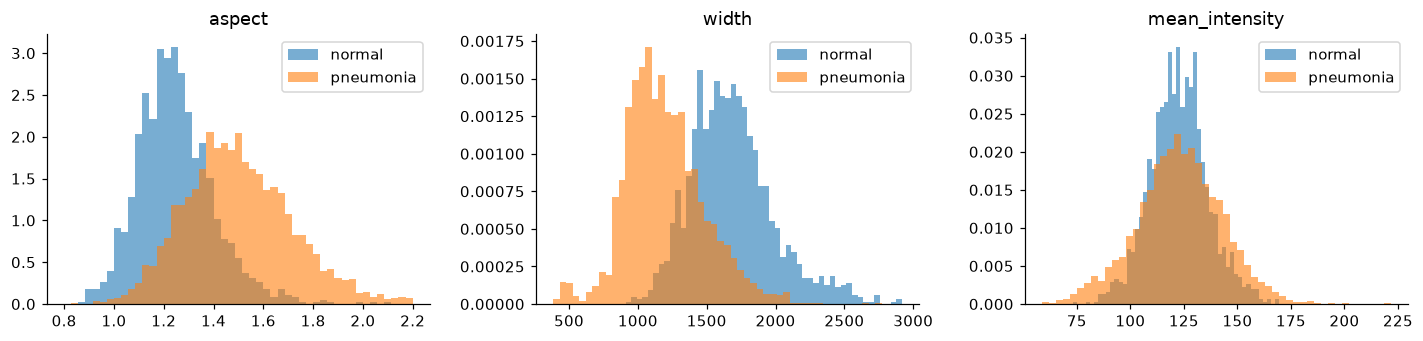

Test-A AUROC from image metadata only (no pixels):
  logistic(width, height, aspect, file size): 0.864
  width           alone: 0.950
  height          alone: 0.920
  aspect          alone: 0.704
  file_bytes      alone: 0.927
  mean_intensity  alone: 0.573
  std_intensity   alone: 0.663


In [3]:
props = ["width", "height", "aspect", "file_bytes", "mean_intensity", "std_intensity"]
display(a.groupby("orig_label")[props].median().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, bins in zip(axes, ["aspect", "width", "mean_intensity"], [np.linspace(0.8, 2.2, 50), 50, 50]):
    for lab, name in [(0, "normal"), (1, "pneumonia")]:
        ax.hist(a.loc[a.label == lab, col], bins=bins, alpha=0.6, density=True, label=name)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "a_acquisition_by_class.png", bbox_inches="tight"); plt.show()

# How far does metadata alone get? Fit on official train, score on official test.
X = lambda d: np.column_stack([np.log(d.width), np.log(d.height), d.aspect, np.log(d.file_bytes)])
tr, te = a[a.official_split != "test"], a[a.official_split == "test"]
clf = LogisticRegression(max_iter=1000).fit(X(tr), tr.label)
single = {c: max(roc_auc_score(te.label, te[c]), 1 - roc_auc_score(te.label, te[c])) for c in props}
print("Test-A AUROC from image metadata only (no pixels):")
print(f"  logistic(width, height, aspect, file size): {roc_auc_score(te.label, clf.predict_proba(X(te))[:, 1]):.3f}")
for c, v in single.items():
    print(f"  {c:15s} alone: {v:.3f}")

**Consequence for preprocessing.** Every image is resized to a square with its full field of view (`squash`).
* *Letterboxing* keeps the aspect ratio but turns the black padding width into a direct encoding of the class-dependent aspect ratio.
* *Center-cropping* removes the lateral lung fields on the wide (mostly pneumonia) images.
* Squashing keeps all anatomy and adds no padding cue. It still distorts anatomy by a class-dependent amount, a weaker residual cue that is acknowledged as a limitation.

B images are square (1024×1024), so they are not distorted at all.

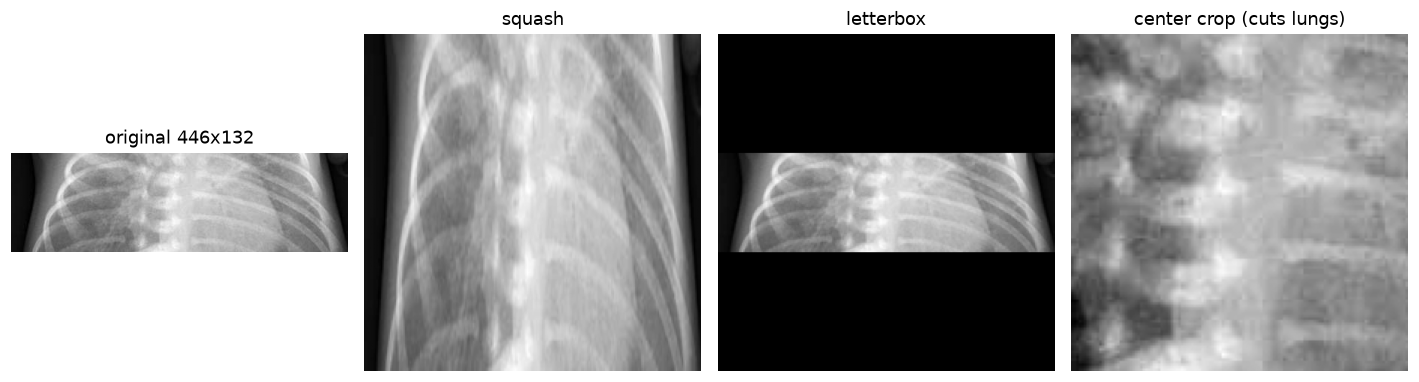

In [4]:
ex = a[a.orig_label != "normal"].sort_values("aspect").iloc[-1]
img = load_gray(ROOT / ex.image_path)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(img, cmap="gray"); axes[0].set_title(f"original {img.shape[1]}x{img.shape[0]}")
for ax, mode in zip(axes[1:3], ["squash", "letterbox"]):
    ax.imshow(to_square(img, IMAGE_SIZE, mode), cmap="gray"); ax.set_title(mode)
h, w = img.shape; c = img[:, (w - h) // 2:(w - h) // 2 + h]
axes[3].imshow(c, cmap="gray"); axes[3].set_title("center crop (cuts lungs)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "a_resize_modes.png", bbox_inches="tight"); plt.show()

## 3. Patient overlap and near-duplicates

### 3a. The official train/test split is not patient-disjoint

In [5]:
pn = a[a.label == 1]
mixed = pn.groupby(["official_split", "patient_id"]).orig_label.nunique().gt(1).groupby(level=0).agg(["sum", "size"])
mixed.columns = ["patients with both bacterial and viral images", "patients"]
display(mixed)

pool_ids = set(a.loc[a.official_split != "test", "patient_id"])
test_ids = set(a.loc[a.official_split == "test", "patient_id"])
shared = pool_ids & test_ids
print(f"patient IDs present in both official train/val and test: {len(shared)} "
      f"({a[a.patient_id.isin(shared) & (a.official_split != 'test')].shape[0]} train/val images, "
      f"{a[a.patient_id.isin(shared) & (a.official_split == 'test')].shape[0]} test images)")
print("of which normal-class IDs:", sum(not s.startswith("person") for s in shared))

,patients with both bacterial and viral images,patients
official_split,,
test,1,202
train,808,1635
val,0,7


patient IDs present in both official train/val and test: 170 (457 train/val images, 320 test images)
of which normal-class IDs: 0


Pneumonia patient IDs are not specific to one pathogen: about half the training patients have both bacterial and viral images, and the per-pathogen image counters are global and disjoint. So `personN` in `train/` and `personN` in `test/` should be treated as **the same child**.

**Decision.** Keep the official test set intact as *Test A*, so results stay comparable with the literature. Remove the shared patients' images from the training pool. This is conservative: if the IDs were actually unrelated, we only lose some training images.

### 3b. Near-duplicate images

64-bit perceptual hashes do not work on chest X-rays: thousands of different patients collide. Instead each image is embedded as a zero-mean, unit-norm 32×32 thumbnail, and pairs are compared by cosine similarity.

,pairs,same_patient,cross_split
band,,,
"(0.97, 0.98]",58,0.034483,9
"(0.98, 0.99]",0,NaN,0
"(0.99, 0.995]",0,NaN,0
"(0.995, 1.001]",34,0.970588,0


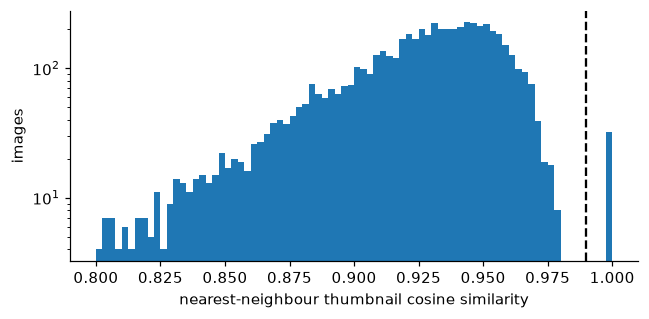

In [6]:
sim = thumbs @ thumbs.T
np.fill_diagonal(sim, -1)
nearest = sim.max(1)
i, j = np.where(np.triu(sim >= 0.97))
pairs = pd.DataFrame({"i": i, "j": j, "sim": sim[i, j]})
pairs["same_patient"] = (a.patient_id.values[i] == a.patient_id.values[j]) & \
                        ((a.official_split.values[i] == "test") == (a.official_split.values[j] == "test"))
pairs["cross_split"] = a.official_split.values[i] != a.official_split.values[j]
pairs["band"] = pd.cut(pairs.sim, [0.97, 0.98, 0.99, 0.995, 1.001])
display(pairs.groupby("band", observed=False).agg(pairs=("sim", "size"), same_patient=("same_patient", "mean"),
                                                   cross_split=("cross_split", "sum")))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(nearest, bins=np.linspace(0.8, 1.0, 81)); ax.axvline(DUP_THRESHOLD, color="k", ls="--")
ax.set_yscale("log"); ax.set_xlabel("nearest-neighbour thumbnail cosine similarity"); ax.set_ylabel("images")
plt.tight_layout(); plt.savefig(FIG / "a_near_duplicates.png", bbox_inches="tight"); plt.show()

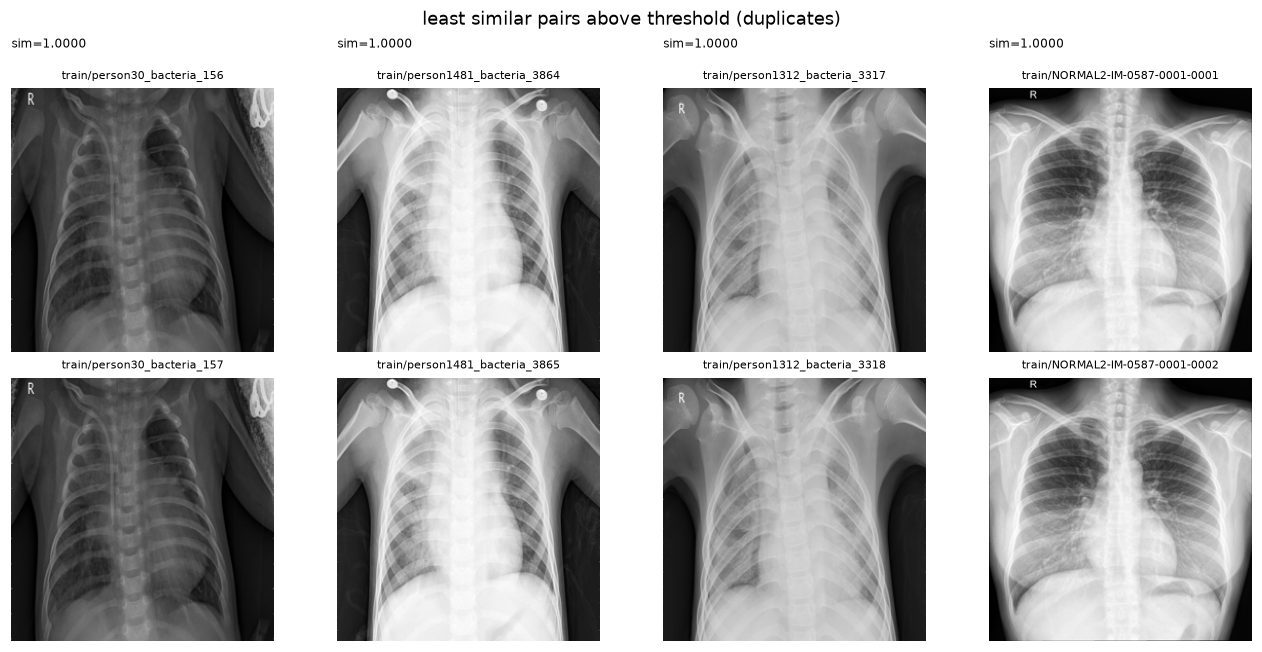

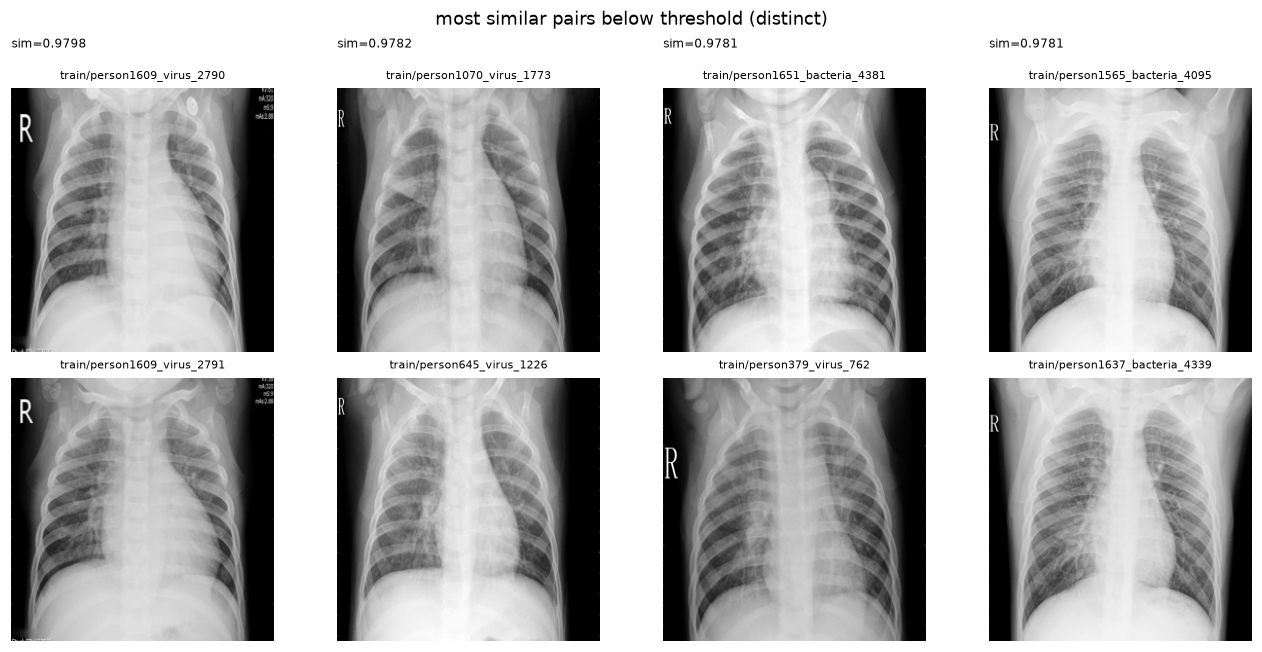

In [7]:
def show_pairs(df, title, n=4):
    df = df.head(n)
    if df.empty:
        print(f"{title}: none"); return
    fig, axes = plt.subplots(2, len(df), figsize=(3 * len(df), 6), squeeze=False)
    for k, r in enumerate(df.itertuples()):
        for row, idx in enumerate([r.i, r.j]):
            axes[row, k].imshow(to_square(load_gray(ROOT / a.image_path[idx]), 256), cmap="gray")
            axes[row, k].set_title(a.image_id[idx].split("/", 1)[1], fontsize=7); axes[row, k].axis("off")
        axes[0, k].text(0, -40, f"sim={r.sim:.4f}", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_pairs(pairs[pairs.sim >= DUP_THRESHOLD].sort_values("sim"), "least similar pairs above threshold (duplicates)")
show_pairs(pairs[pairs.sim < DUP_THRESHOLD].sort_values("sim", ascending=False), "most similar pairs below threshold (distinct)")

Pairs above the threshold are the same image re-saved within one patient. There is a clear gap below them, and the most similar pairs below the threshold are visibly different radiographs. Duplicates are merged into the patient's group anyway, so the split stays leakage-free even if a future data version contains cross-patient copies.

## 4. Grouping and splitting

In [8]:
# Union-find over images: same patient (within the official test namespace or the train/val namespace,
# unified via the overlap decision above) or near-duplicate -> same group.
parent = list(range(len(a)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(x, y):
    parent[find(x)] = find(y)

for _, idx in a.groupby("patient_id").indices.items():
    for k in idx[1:]:
        union(idx[0], k)
for r in pairs[pairs.sim >= DUP_THRESHOLD].itertuples():
    union(r.i, r.j)
roots = np.array([find(k) for k in range(len(a))])
a["group_id"] = pd.factorize(roots)[0]

test_groups = set(a.loc[a.official_split == "test", "group_id"])
a["split"] = np.where(a.official_split == "test", "test", "pool")
a["excluded_reason"] = ""
leak = (a.split == "pool") & a.group_id.isin(test_groups)
a.loc[leak, ["split", "excluded_reason"]] = ["excluded", "patient shared with official test"]

pool = a[a.split == "pool"]
sgkf = StratifiedGroupKFold(n_splits=VAL_FOLDS, shuffle=True, random_state=SEED)
_, val_pos = next(sgkf.split(pool, pool.label, pool.group_id))
a.loc[pool.index, "split"] = "train"
a.loc[pool.index[val_pos], "split"] = "val"

# Nested, class-balanced training subsets: one random image per patient, then a random per-class rank.
# "subset_rank < k" gives k patients per class, and smaller subsets are contained in larger ones, so
# "1k real + 25% more real" (rank < 625) is the matched control for "1k real + 25% synthetic".
one_per_patient = a[a.split == "train"].sample(frac=1, random_state=SEED).drop_duplicates("group_id")
one_per_patient["subset_rank"] = one_per_patient.groupby("label").cumcount()
a["subset_rank"] = one_per_patient["subset_rank"].reindex(a.index)
a["subset_1k"] = a.subset_rank < SUBSET_PER_CLASS
print("max balanced subset size:", 2 * int(one_per_patient.groupby("label").size().min()), "images")

# Leakage checks
for s1, s2 in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(a.group_id[a.split == s1]) & set(a.group_id[a.split == s2]), (s1, s2)
assert a[a.subset_1k].split.eq("train").all() and a[a.subset_1k].group_id.is_unique

tab = a.groupby(["split", "label"]).agg(images=("image_id", "size"), patients=("group_id", "nunique")).unstack()
tab.loc["subset_1k (train)"] = a[a.subset_1k].groupby("label").agg(images=("image_id", "size"), patients=("group_id", "nunique")).unstack().reindex(tab.columns)
display(tab)
display(a.groupby("split").label.mean().rename("pneumonia prevalence").to_frame().T.round(3))

max balanced subset size: 2090 images


images         patients        
label                   0       1        0       1
split                                             
excluded              NaN   457.0      NaN   170.0
test                234.0   390.0    224.0   202.0
train              1156.0  2937.0   1045.0  1262.0
val                 193.0   489.0    174.0   210.0
subset_1k (train)   500.0   500.0    500.0   500.0

split,excluded,test,train,val
pneumonia prevalence,1.0,0.625,0.718,0.717


### Shortcut check on our own splits
Fit a metadata-only classifier (no pixels: width, height, aspect ratio, file size) on the 1,000 E1 training images and score it on our validation set and on Test A. It shows how much of the task can be solved from acquisition properties alone, and explains why every CNN reaches validation AUROC of about 0.99 within 50 steps (see `docs/report.md`, section 2.1).

In [9]:
X = lambda d: np.column_stack([np.log(d.width), np.log(d.height), d.aspect, np.log(d.file_bytes)])
fit_on = a[(a.split == "train") & a.subset_1k]
meta_clf = LogisticRegression(max_iter=2000).fit(X(fit_on), fit_on.label)
shortcut = pd.DataFrame({
    s: {"metadata-only logistic (no pixels)": roc_auc_score(a[a.split == s].label, meta_clf.predict_proba(X(a[a.split == s]))[:, 1]),
        "image width alone": 1 - roc_auc_score(a[a.split == s].label, a[a.split == s].width)}
    for s in ["val", "test"]}).rename(columns={"val": "A-validation AUROC", "test": "Test A AUROC"})
display(shortcut.round(3))

,A-validation AUROC,Test A AUROC
metadata-only logistic (no pixels),0.998,0.905
image width alone,0.856,0.950


In [10]:
cols = ["image_id", "image_path", "label", "orig_label", "source", "split", "official_split", "patient_id",
        "group_id", "subset_rank", "subset_1k", "excluded_reason", "width", "height", "aspect", "file_bytes",
        "mean_intensity", "std_intensity"]
a[cols].to_csv(MANIFESTS / "kermany.csv", index=False)
print("wrote", MANIFESTS / "kermany.csv", len(a), "rows")

images, row_of = ensure_cache(MANIFESTS / "kermany.csv", IMAGE_SIZE, RESIZE_MODE)
print("cache:", images.shape, images.dtype)

wrote /home/edelweizse/Projects/uni/AIE/final/artifacts/manifests/kermany.csv 5856 rows
cache: (5856, 224, 224) uint8


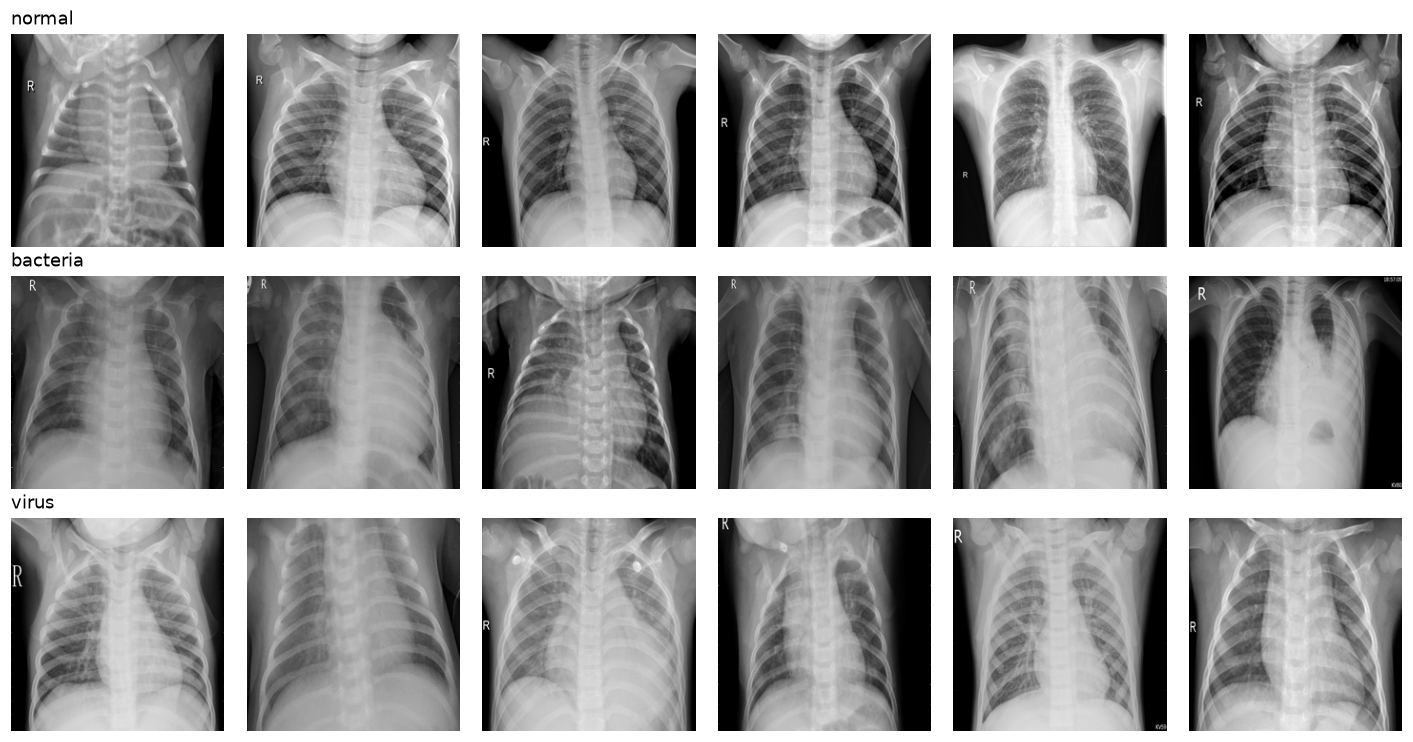

In [11]:
# What the classifier sees (224x224, squash), from the cache
fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
for r, cls in enumerate(["normal", "bacteria", "virus"]):
    ids = a[(a.orig_label == cls) & (a.split == "train")].sample(6, random_state=SEED).image_id
    for c, iid in enumerate(ids):
        axes[r, c].imshow(images[row_of[iid]], cmap="gray", vmin=0, vmax=255); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left")
plt.tight_layout(); plt.savefig(FIG / "a_samples.png", bbox_inches="tight"); plt.show()

## 5. Dataset B: label harmonisation

**Background.** B is the 2018 RSNA Pneumonia Detection Challenge data: 30,000 frontal radiographs sampled from the NIH ChestX-ray14 collection (NIH Clinical Center, USA; mostly adults). Radiologists from RSNA and the Society of Thoracic Radiology re-annotated them on the MD.ai platform. Each study was read by multiple radiologists, and disagreements were adjudicated. This is a much more rigorous labelling process than A's, where labels come from clinical diagnoses graded by two physicians.

The MD.ai export contains reads from several teams plus adjudication. The **`Calculated`** label group is the final consensus label used for the Kaggle challenge: exactly one class per study.

| B class | Meaning | Primary task (`label`) | Secondary (`label_any`) |
|---|---|---|---|
| Lung Opacity | opacity suspicious for pneumonia (bbox) | **1** | 1 |
| Normal | normal radiograph | **0** | 0 |
| No Lung Opacity / Not Normal | other abnormality, not pneumonia-like | *excluded* | 0 |

A's negatives are *normal* children, so the like-for-like external task is **Lung Opacity vs Normal**. Counting "not normal" studies as negatives is a harder, different task: the model has never seen non-pneumonia abnormalities. It is reported as a secondary analysis.

Note that A's labels are clinical pneumonia diagnoses, while B's are radiological *opacity* findings: related, but not identical definitions. B is also adult and A is pediatric. Both are part of the domain shift we are measuring.

In [12]:
d = json.loads(B_JSON.read_text())
label_name = {l["id"]: (g["name"], l["name"].strip()) for g in d["labelGroups"] for l in g["labels"]}
ann = d["datasets"][0]["annotations"]

calc = collections.defaultdict(list)
uids = {}
for x in ann:
    group, name = label_name[x["labelId"]]
    if group == "Calculated":
        calc[x["StudyInstanceUID"]].append(name)
        uids[x["StudyInstanceUID"]] = (x.get("SeriesInstanceUID"), x.get("SOPInstanceUID"))

b_labels = pd.DataFrame([
    {"study_uid": s, "series_uid": uids[s][0], "sop_uid": uids[s][1],
     "class3": names[0], "n_boxes": names.count("Lung Opacity")}
    for s, names in calc.items()
])
assert b_labels.groupby("study_uid").class3.nunique().eq(1).all()
b_labels["label"] = b_labels.class3.map({"Lung Opacity": 1, "Normal": 0})          # NaN for 'not normal'
b_labels["label_any"] = (b_labels.class3 == "Lung Opacity").astype(int)
b_labels.to_csv(MANIFESTS / "rsna_labels.csv", index=False)

print(f"{len(d['datasets'][0]['studies'])} studies in export, {len(b_labels)} with a consensus label")
display(b_labels.class3.value_counts().to_frame("studies").assign(share=lambda t: (t.studies / t.studies.sum()).round(3)))
print(f"primary task: {b_labels.label.notna().sum()} studies, prevalence {b_labels.label.mean():.3f}")

30000 studies in export, 29684 with a consensus label


,studies,share
class3,,
No Lung Opacity / Not Normal,12788,0.431
Normal,9790,0.330
Lung Opacity,7106,0.239


primary task: 16896 studies, prevalence 0.421


**Why this harmonisation matters**
* *Prevalence differs*: about 42% positives in the primary B task vs 63% in Test A. AUROC is prevalence-independent; precision and F1 are not, so F1 is not comparable across datasets.
* *Definitions differ*: "pneumonia" in A is a clinical diagnosis in a child. "Lung opacity" in B is a radiological sign in a mostly adult population, and opacity can also come from other causes (oedema, haemorrhage, atelectasis). Some B "positives" would not be called pneumonia clinically, and vice versa. A perfect A-classifier would therefore still not reach AUROC 1.0 on B.
* *"Not normal" is out-of-distribution for A*: A has no class for nodules, effusions, devices, cardiomegaly and the like. The secondary task shows how the model reacts to such abnormal-but-not-pneumonia images. A large share of them are expected to be scored as pneumonia, because the model never learned that "abnormal" and "pneumonia" are different things.

## 6. Dataset B: image manifest

Extract the RSNA image archive into `data/rsna/` and re-run from here. Files are matched to labels by DICOM `StudyInstanceUID`, or by UID in the file name for PNG/JPEG exports.

In [13]:
def b_header(path):
    path = Path(path)
    if path.suffix.lower() == ".dcm":
        import pydicom
        h = pydicom.dcmread(path, stop_before_pixels=True)
        age = str(getattr(h, "PatientAge", "")).rstrip("Y") or None
        return {"study_uid": h.StudyInstanceUID, "patient_id": str(getattr(h, "PatientID", h.StudyInstanceUID)),
                "age": float(age) if age and age.isdigit() else np.nan, "sex": getattr(h, "PatientSex", None),
                "view": getattr(h, "ViewPosition", None), "height": int(h.Rows), "width": int(h.Columns)}
    return {"uid_from_name": path.stem}

b_files = sorted(p for p in B_DIR.rglob("*") if p.suffix.lower() in {".dcm", ".png", ".jpg", ".jpeg"}) if B_DIR.exists() else []
if not b_files:
    print(f"No B images under {B_DIR} yet. Extract the archive there and re-run sections 6-7.")
else:
    with Pool(12) as pool:
        heads = pool.map(b_header, b_files, chunksize=64)
    bf = pd.DataFrame(heads)
    bf["image_path"] = [str(p.relative_to(ROOT)) for p in b_files]
    if "study_uid" not in bf:  # PNG/JPEG export: file name is one of the UIDs
        by_uid = {u: s for s, se, so in b_labels[["study_uid", "series_uid", "sop_uid"]].itertuples(index=False) for u in (s, se, so)}
        bf["study_uid"] = bf.uid_from_name.map(by_uid)
        bf["patient_id"] = bf.study_uid
    b = bf.merge(b_labels, on="study_uid", how="inner")
    print(f"{len(b_files)} files, {len(b)} matched to a consensus label, "
          f"{b_labels.study_uid.isin(bf.study_uid).mean():.1%} of labelled studies found")
    b["image_id"] = "B/" + b.study_uid
    b["source"], b["split"] = "rsna", "external"
    b = b.drop_duplicates("image_id")
    bcols = ["image_id", "image_path", "label", "label_any", "class3", "n_boxes", "source", "split",
             "patient_id", "study_uid", "age", "sex", "view", "width", "height"]
    b = b[[c for c in bcols if c in b]]
    b.to_csv(MANIFESTS / "rsna.csv", index=False)
    print("wrote", MANIFESTS / "rsna.csv", len(b), "rows")

30000 files, 29684 matched to a consensus label, 100.0% of labelled studies found


wrote /home/edelweizse/Projects/uni/AIE/final/artifacts/manifests/rsna.csv 29684 rows


## 7. Dataset B: EDA and domain comparison with A

view,AP,PA,All
class3,,,
Lung Opacity,5492,1614,7106
No Lung Opacity / Not Normal,6268,6520,12788
Normal,1795,7995,9790
All,13555,16129,29684


,age_median,female
class3,,
Lung Opacity,48.0,0.41
No Lung Opacity / Not Normal,52.0,0.43
Normal,46.0,0.44


image sizes: {(1024, 1024): 29684}


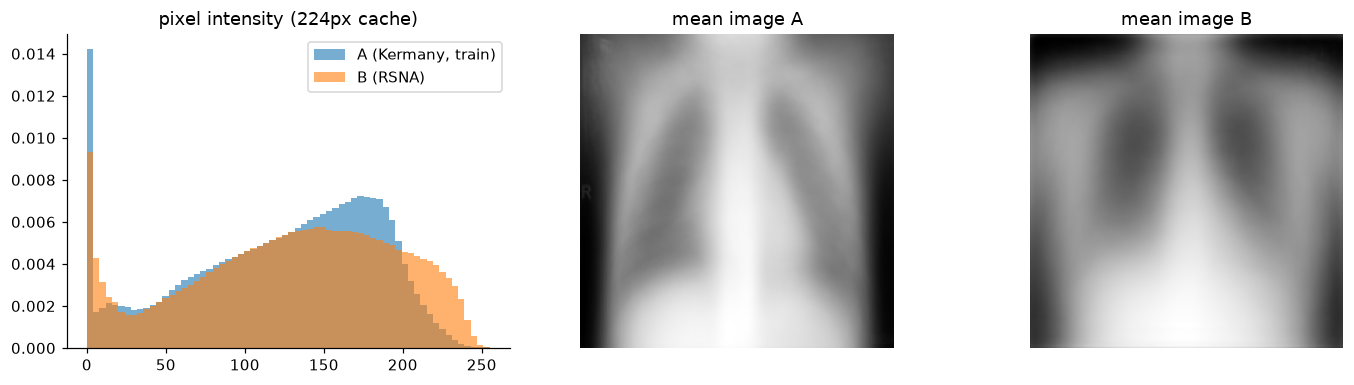

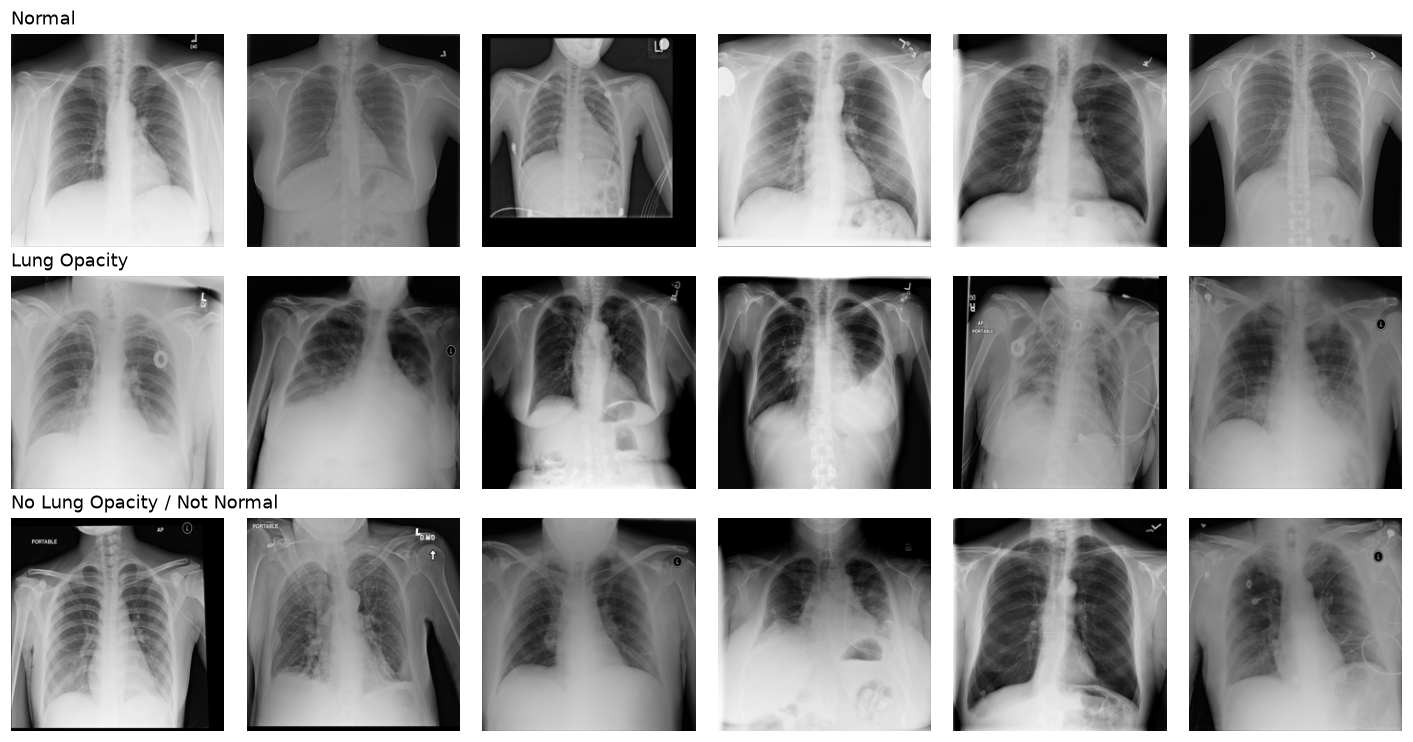

In [14]:
if (MANIFESTS / "rsna.csv").exists():
    b = pd.read_csv(MANIFESTS / "rsna.csv")
    display(pd.crosstab(b.class3, b.view, margins=True) if "view" in b else b.class3.value_counts())
    if "age" in b:
        display(b.groupby("class3").agg(age_median=("age", "median"), female=("sex", lambda s: (s == "F").mean())).round(2))
    print("image sizes:", b.groupby(["width", "height"]).size().sort_values(ascending=False).head(3).to_dict())

    b_images, b_row = ensure_cache(MANIFESTS / "rsna.csv", IMAGE_SIZE, RESIZE_MODE)
    rng = np.random.default_rng(SEED)
    a_idx = [row_of[i] for i in a[a.split == "train"].sample(500, random_state=SEED).image_id]
    b_idx = rng.choice(len(b_images), 500, replace=False)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    for name, arr in [("A (Kermany, train)", images[sorted(a_idx)]), ("B (RSNA)", b_images[np.sort(b_idx)])]:
        axes[0].hist(arr.ravel(), bins=64, density=True, alpha=0.6, label=name)
    axes[0].set_title("pixel intensity (224px cache)"); axes[0].legend()
    axes[1].imshow(images[sorted(a_idx)].mean(0), cmap="gray"); axes[1].set_title("mean image A")
    axes[2].imshow(b_images[np.sort(b_idx)].mean(0), cmap="gray"); axes[2].set_title("mean image B")
    for ax in axes[1:]: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG / "ab_domain_comparison.png", bbox_inches="tight"); plt.show()

    fig, axes = plt.subplots(3, 6, figsize=(13, 6.8))
    for r, cls in enumerate(["Normal", "Lung Opacity", "No Lung Opacity / Not Normal"]):
        for c, iid in enumerate(b[b.class3 == cls].sample(6, random_state=SEED).image_id):
            axes[r, c].imshow(b_images[b_row[iid]], cmap="gray", vmin=0, vmax=255); axes[r, c].axis("off")
        axes[r, 0].set_title(cls, loc="left")
    plt.tight_layout(); plt.savefig(FIG / "b_samples.png", bbox_inches="tight"); plt.show()
else:
    print("B manifest not built yet.")

**Reading the B EDA**
* **View position (AP vs PA) is entangled with the label.** AP films are taken with portable machines, typically for inpatients too sick to stand. They carry opacity in about 40% of studies, versus about 10% for PA films, and Normal studies are mostly PA. A classifier can partly "solve" B by recognising AP-style images (different magnification, scapulae over the lungs, ECG leads and lines). The pooled B AUROC therefore overstates true opacity detection, and within-view AUROC is reported as a robustness check (notebooks 03–05).
* **Age.** B is mostly adults (median about 49 y), but it includes about 1,000 patients under 18 in the primary task. That pediatric slice is the closest thing to A's population and is analysed separately. A few ages are impossible (>100, e.g. 412). They are data-entry errors in the source metadata and are treated as missing.
* **Intensity and appearance.** The mean images show the different framing (B adults: larger thorax, different collimation; A: small children, often with arms raised and more of the abdomen visible). Intensity histograms differ because of different detectors and post-processing. Both are classic sources of domain shift that the classifier has to survive.

## Key takeaways from data preparation
1. **The official Kermany split leaks patients** (170 shared IDs). Fixed by excluding those patients from training, while keeping the official test set intact for comparability.
2. **A contains a strong acquisition shortcut.** File metadata alone separates the classes (validation AUROC 0.998 without pixels). Expect every CNN to look nearly perfect on A-validation. Discrimination that only shows up on A says little, which is why B exists.
3. **Preprocessing was chosen to avoid creating new shortcuts**: full-field-of-view resize instead of letterboxing (padding would encode aspect ratio, which depends on class in A).
4. **B is a hard, honest external test**: different population (adults), country, equipment and labelling process, and a slightly different label definition (radiological opacity vs clinical pneumonia).
5. **B has its own confounder** (AP/PA view vs label), so B results are also reported within view.